In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
df=pd.read_csv("Salary_Data.csv")

In [3]:
df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [4]:
df.describe()

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


In [5]:
df.isnull().sum()

YearsExperience    0
Salary             0
dtype: int64

In [6]:
df.duplicated().sum()

0

In [7]:
df.shape

(30, 2)

In [8]:
df.columns

Index(['YearsExperience', 'Salary'], dtype='object')

<Axes: xlabel='Salary', ylabel='Density'>

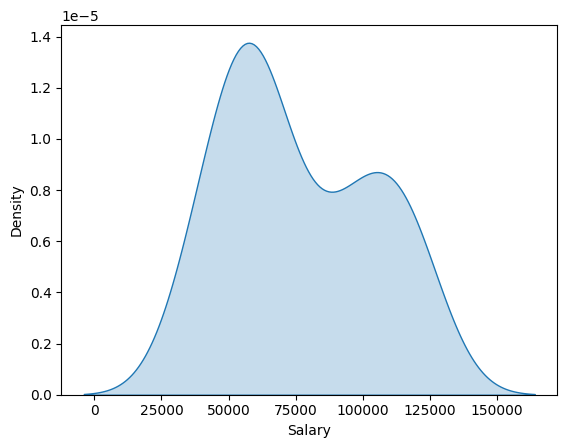

In [9]:
sns.kdeplot(data=df,x='Salary', fill=True)

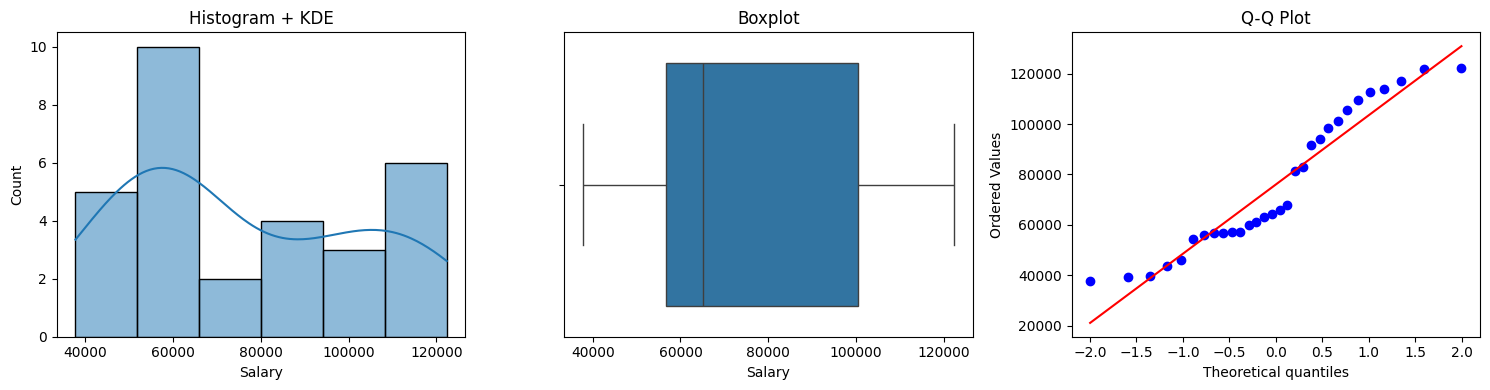

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Histogram + KDE
sns.histplot(data=df, x='Salary', kde=True, ax=axes[0])
axes[0].set_title("Histogram + KDE")

# Boxplot
sns.boxplot(data=df, x='Salary', ax=axes[1])
axes[1].set_title("Boxplot")

# Q-Q plot
stats.probplot(df['Salary'], dist="norm", plot=axes[2])
axes[2].set_title("Q-Q Plot")

plt.tight_layout()
plt.show()

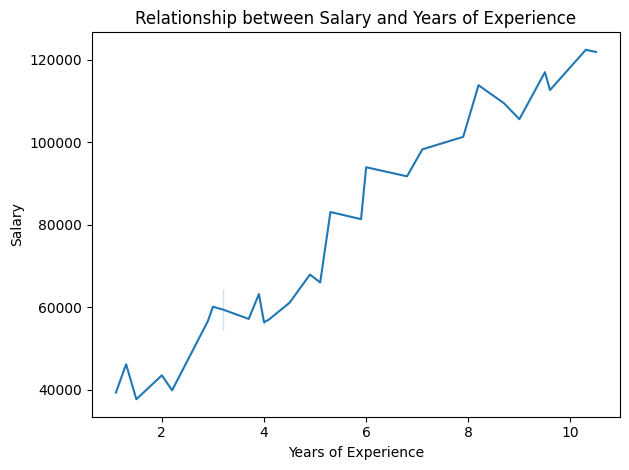

In [11]:
sns.lineplot(data=df,x='YearsExperience',y='Salary')
plt.title("Relationship between Salary and Years of Experience")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.tight_layout()
plt.show()

In [12]:
from sklearn.model_selection import train_test_split

In [ ]:
X=df[['YearsExperience']]
y=df['Salary']

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.2)

In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso

In [22]:
model=LinearRegression()
ridge=Ridge()
lasso=Lasso()

In [24]:
model.fit(X_train,y_train)
ridge.fit(X_train,y_train)
lasso.fit(X_train,y_train)

,alpha,1.0
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [25]:
y_pred=model.predict(X_test)
ridge_y_pred=ridge.predict(X_test)
lasso_y_pred=lasso.predict(X_test)

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score


In [ ]:

print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²  :", r2_score(y_test, y_pred))
print("---------------------------------------------")
print("---------------------------------------------")
print("MAE :", mean_absolute_error(y_test,ridge_y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, ridge_y_pred)))
print("R²  :", r2_score(y_test, ridge_y_pred))
print("---------------------------------------------")
print("---------------------------------------------")
print("MAE :", mean_absolute_error(y_test, lasso_y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lasso_y_pred)))
print("R²  :", r2_score(y_test, lasso_y_pred))

MAE : 6286.453830757749
RMSE: 7059.04362190151
R²  : 0.9024461774180497
